# Reconocimiento de actividades humanas con una CNN 1D
**Módulo 2 · Implementación de un modelo de deep learning · Modalidad individual**

Este cuaderno desarrolla una solución con TensorFlow y Keras; además, conserva las salidas del análisis, compara ajustes y permite cargar el modelo para realizar predicciones.


## 1. Introducción
El problema consiste en identificar seis actividades a partir de señales de movimiento de un teléfono; para ello, se utiliza una red convolucional de una dimensión, capaz de aprender patrones en el tiempo. Esta tarea puede apoyar el seguimiento de actividad física y el desarrollo de aplicaciones móviles; sin embargo, este experimento no constituye un sistema médico ni garantiza resultados con cualquier dispositivo.

La entrada es una ventana de 128 instantes y nueve canales; la salida es una de seis clases. El objetivo es comparar una CNN inicial con variantes regularizadas y seleccionar la de mayor F1 macro en validación; esta métrica da el mismo peso a cada actividad, mientras que accuracy muestra la proporción total de aciertos.

UCI HAR resulta apropiado porque proviene de mediciones reales, conserva una estructura temporal y tiene un tamaño manejable; aunque es un benchmark conocido, no es un conjunto sintético de juguete. Se elige la fuente original para conservar las señales y los identificadores de participantes.

### Preparación del entorno
Primero se importan las bibliotecas y se fija la semilla; asimismo, se crean las carpetas de trabajo que utiliza la ejecución. El cuaderno conserva los resultados obtenidos y el modelo entrenado se entrega en `models/modelo_final.keras`; los archivos auxiliares se generan al ejecutar y no se necesitan como archivos separados para revisar el reporte.

Para repetir el análisis, utiliza Python 3.12 con TensorFlow, Keras, NumPy, pandas, scikit-learn, matplotlib e IPython; las versiones principales utilizadas fueron TensorFlow 2.21.0 y Keras 3.15.1. Si necesitas instalar las bibliotecas, ejecuta en la terminal del entorno:

```bash
python -m pip install tensorflow==2.21.0 keras==3.15.1 numpy==2.5.4 pandas==3.1.1 scikit-learn==1.9.1 matplotlib==3.11.2 ipython
```

Abre este cuaderno desde su carpeta y ejecuta las celdas en orden; la descarga inicial requiere internet. Las tablas, gráficas y predicciones ya incluidas pueden revisarse sin volver a entrenar.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import sys, json, hashlib, platform, time, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display, Markdown

SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for folder in ['data', 'models', 'reports/figures', 'examples']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
CLASES = ['Caminar', 'Subir escaleras', 'Bajar escaleras', 'Sentarse', 'Estar de pie', 'Acostarse']
CANALES = [f'{sensor}_{eje}' for sensor in ['body_acc', 'body_gyro', 'total_acc'] for eje in 'xyz']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version(), '| TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('Dispositivos GPU:', len(tf.config.list_physical_devices('GPU')))
print('Semilla:', SEED, '| Carpeta:', ROOT.name)

Python: 3.12.14 | TensorFlow: 2.21.0 | Keras: 3.15.1


Dispositivos GPU: 0
Semilla: 42 | Carpeta: actividad_har


## 2. Datos
Se utiliza [Human Activity Recognition Using Smartphones, de UCI](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones); contiene 10 299 ventanas de 30 voluntarios, de entre 19 y 48 años, con seis actividades etiquetadas. Las señales se registraron a 50 Hz y se organizaron en ventanas de 2.56 segundos con 50 % de traslape; por ello, dividir ventanas al azar podría producir una evaluación demasiado optimista.

Se conservan los participantes de prueba definidos por los autores; dentro del entrenamiento original se apartan otras personas para validación. Se utilizan las nueve señales temporales de `Inertial Signals`, y no la tabla de 561 características calculadas; los canales corresponden a aceleración corporal, velocidad angular y aceleración total en tres ejes.

Las señales ya fueron filtradas y segmentadas por los autores; por tanto, no deben describirse como lecturas crudas sin procesar. La aceleración se expresa en unidades de gravedad y el giroscopio en radianes por segundo, según la documentación incluida; el orden de canales se conserva tanto al entrenar como al predecir.

**Fuente:** Reyes-Ortiz, J., Anguita, D., Ghio, A., Oneto, L. y Parra, X. (2013), UCI Machine Learning Repository; DOI: [10.24432/C54S4K](https://doi.org/10.24432/C54S4K). La ficha de UCI indica licencia CC BY 4.0; se mantiene la atribución y la documentación original en la descarga.

Se descarga el archivo desde UCI si todavía no está disponible; después se extraen los datos y se registra su huella digital para identificar la versión utilizada.

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
archivo = ROOT / 'data/uci_har.zip'
if not archivo.exists():
    with urllib.request.urlopen(URL, timeout=120) as respuesta:
        archivo.write_bytes(respuesta.read())

def extraer_seguro(ruta, destino):
    with zipfile.ZipFile(ruta) as z:
        for miembro in z.infolist():
            objetivo = (destino / miembro.filename).resolve()
            if not objetivo.is_relative_to(destino.resolve()):
                raise ValueError('El archivo contiene una ruta no permitida')
        z.extractall(destino)

carpeta = ROOT / 'data/UCI HAR Dataset'
if not carpeta.exists():
    extraer_seguro(archivo, ROOT / 'data')
    for interno in (ROOT / 'data').rglob('UCI HAR Dataset.zip'):
        extraer_seguro(interno, ROOT / 'data')
coincidencias = list((ROOT / 'data').rglob('activity_labels.txt'))
assert coincidencias, 'No se encontró la estructura de UCI HAR'
carpeta = coincidencias[0].parent
huella = hashlib.sha256(archivo.read_bytes()).hexdigest()
(ROOT / 'reports/fuente.json').write_text(json.dumps({'url': URL, 'sha256': huella}, indent=2))
print('Descarga verificada:', round(archivo.stat().st_size / 1e6, 2), 'MB')
print('SHA-256:', huella)

Descarga verificada: 61.01 MB
SHA-256: c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031


Se cargan las señales en un arreglo con dimensiones ventana, tiempo y canal; además, se revisan las etiquetas y los valores faltantes antes de continuar.

In [3]:
def cargar_particion(nombre):
    base = carpeta / nombre
    x = np.stack([np.loadtxt(base / 'Inertial Signals' / f'{c}_{nombre}.txt', dtype=np.float32)
                  for c in CANALES], axis=-1)
    y = np.loadtxt(base / f'y_{nombre}.txt', dtype=int) - 1
    sujetos = np.loadtxt(base / f'subject_{nombre}.txt', dtype=int)
    assert x.shape == (len(y), 128, 9)
    assert len(y) == len(sujetos) and np.isfinite(x).all()
    assert set(np.unique(y)) == set(range(6))
    return x, y, sujetos

X_original, y_original, personas_original = cargar_particion('train')
X_test, y_test, personas_test = cargar_particion('test')
assert len(X_original) == 7352 and len(X_test) == 2947
print('Entrenamiento original:', X_original.shape, '| Prueba reservada:', X_test.shape)
print('Valores no finitos:', int((~np.isfinite(X_original)).sum()))
print('Canales:', CANALES)

Entrenamiento original: (7352, 128, 9) | Prueba reservada: (2947, 128, 9)
Valores no finitos: 0
Canales: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']


Se aparta aproximadamente una cuarta parte de los participantes del entrenamiento original para validar; de esta manera, ninguna persona aparece en más de una partición.

In [4]:
division = GroupShuffleSplit(n_splits=1, test_size=0.24, random_state=SEED)
idx_train, idx_val = next(division.split(X_original, y_original, personas_original))
X_train, X_val = X_original[idx_train], X_original[idx_val]
y_train, y_val = y_original[idx_train], y_original[idx_val]
p_train, p_val = personas_original[idx_train], personas_original[idx_val]
assert set(p_train).isdisjoint(p_val)
assert set(p_train).isdisjoint(personas_test)
assert set(p_val).isdisjoint(personas_test)
assert set(y_train) == set(y_val) == set(y_test) == set(range(6))
particiones = {'entrenamiento': sorted(set(p_train.tolist())),
               'validacion': sorted(set(p_val.tolist())),
               'prueba': sorted(set(personas_test.tolist()))}
(ROOT / 'reports/particiones.json').write_text(json.dumps(particiones, indent=2))
display(pd.DataFrame([{'Partición': k, 'Ventanas': n, 'Personas': len(particiones[k]),
                       'Identificadores': str(particiones[k])}
                      for k, n in zip(particiones, [len(X_train), len(X_val), len(X_test)])]))
print('Comprobación correcta: no hay participantes compartidos')

,Partición,Ventanas,Personas,Identificadores
0,entrenamiento,5270,15,"[5, 6, 7, 11, 14, 16, 17, 19, 21, 22, 23, 26, ..."
1,validacion,2082,6,"[1, 3, 8, 15, 25, 27]"
2,prueba,2947,9,"[2, 4, 9, 10, 12, 13, 18, 20, 24]"


Comprobación correcta: no hay participantes compartidos


Se explora únicamente el entrenamiento para observar la distribución de actividades y la escala de los canales; además, se grafica una ventana de cada clase para reconocer sus diferencias temporales.

,Ventanas de entrenamiento
Caminar,840
Subir escaleras,756
Bajar escaleras,706
Sentarse,947
Estar de pie,999
Acostarse,1022


,Canal,Media,Desviación,Mínimo,Máximo
0,body_acc_x,-0.000564,0.199202,-1.232238,1.299912
1,body_acc_y,-0.000260,0.119836,-1.345267,0.853757
2,body_acc_z,-0.000278,0.109161,-1.202754,1.066916
3,body_gyro_x,-0.001166,0.402224,-4.733656,4.155473
4,body_gyro_y,-0.000575,0.387823,-5.974330,5.746062
5,body_gyro_z,-0.000607,0.260472,-2.763014,2.365982
6,total_acc_x,0.800147,0.419360,-0.373866,2.197618
7,total_acc_y,0.026295,0.383709,-1.582079,1.108593
8,total_acc_z,0.080413,0.373781,-1.639609,1.224664


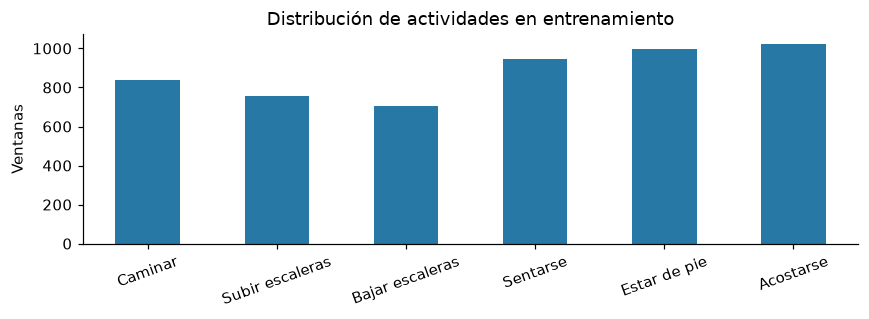

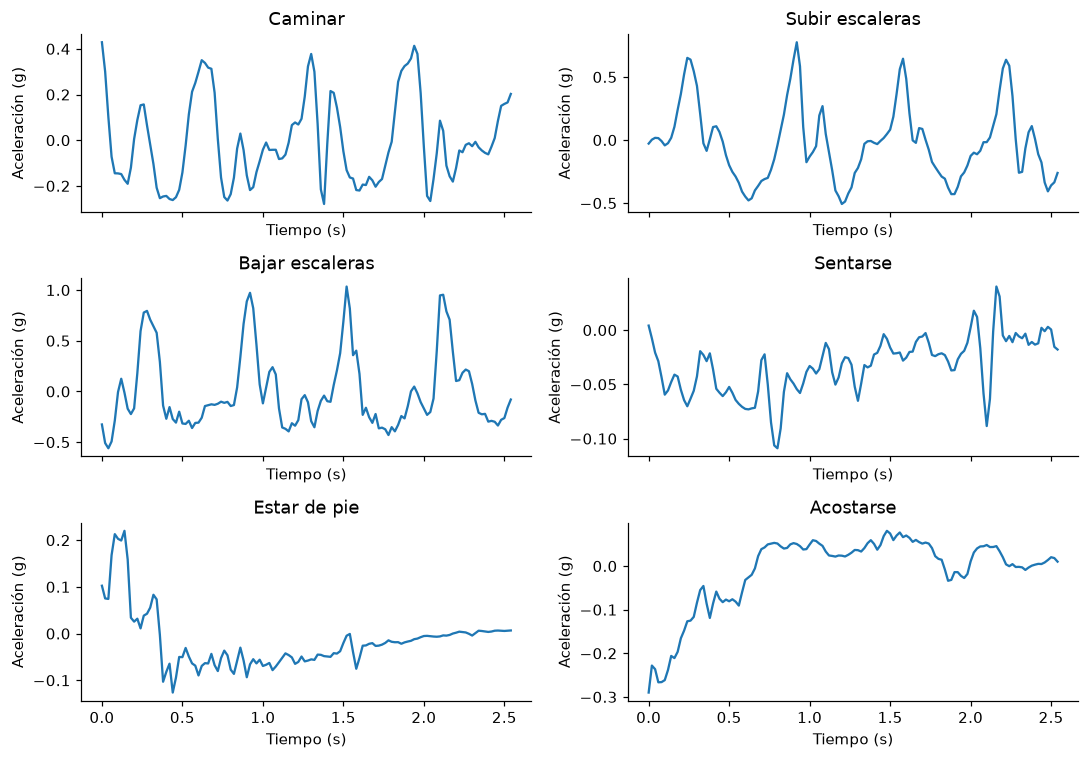

Referencia mayoritaria en validación: Acostarse
Accuracy: 0.1849; F1 macro: 0.0520


In [5]:
conteos = pd.Series(np.bincount(y_train, minlength=6), index=CLASES, name='Ventanas de entrenamiento')
display(conteos.to_frame())
display(pd.DataFrame({'Canal': CANALES, 'Media': X_train.mean(axis=(0, 1)),
                      'Desviación': X_train.std(axis=(0, 1)),
                      'Mínimo': X_train.min(axis=(0, 1)), 'Máximo': X_train.max(axis=(0, 1))}))
fig, ax = plt.subplots(figsize=(8, 3))
conteos.plot.bar(ax=ax, color='#2878a5', rot=20)
ax.set(ylabel='Ventanas', title='Distribución de actividades en entrenamiento')
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/distribucion.png')
plt.show()
fig, axes = plt.subplots(3, 2, figsize=(10, 7), sharex=True)
for clase, ax in enumerate(axes.flat):
    ventana = X_train[np.flatnonzero(y_train == clase)[0]]
    ax.plot(np.arange(128) / 50, ventana[:, 0], label='Aceleración corporal X')
    ax.set(title=CLASES[clase], xlabel='Tiempo (s)', ylabel='Aceleración (g)')
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/senales.png')
plt.show()
mayoritaria = int(np.argmax(np.bincount(y_train)))
pred_ref = np.full_like(y_val, mayoritaria)
print('Referencia mayoritaria en validación:', CLASES[mayoritaria])
print(f'Accuracy: {accuracy_score(y_val, pred_ref):.4f}; F1 macro: {f1_score(y_val, pred_ref, average="macro"):.4f}')

**Lectura del análisis:** las seis actividades están representadas en entrenamiento; además, los canales presentan escalas distintas, por lo que se aplica normalización por canal. Las ventanas ilustradas muestran variaciones temporales en actividades de movimiento y señales más estables en algunas posturas; sin embargo, una ventana por clase solo sirve como ejemplo y no resume toda su variabilidad.

Se calcula la normalización solo con entrenamiento y se guarda para reutilizarla; posteriormente, esta transformación se integra al modelo para que la aplicación reciba señales en su escala original.

In [6]:
media = X_train.mean(axis=(0, 1))
varianza = X_train.var(axis=(0, 1))
assert np.all(varianza > 0)
np.savez(ROOT / 'models/normalizacion.npz', media=media, varianza=varianza)
metadata = {'clases': CLASES, 'canales': CANALES, 'forma': [128, 9],
            'frecuencia_hz': 50, 'normalizacion_integrada': True,
            'semilla': SEED, 'fuente': URL}
(ROOT / 'models/metadatos.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame({'Canal': CANALES, 'Media de entrenamiento': media, 'Varianza de entrenamiento': varianza}))

,Canal,Media de entrenamiento,Varianza de entrenamiento
0,body_acc_x,-0.000564,0.039682
1,body_acc_y,-0.000260,0.014361
2,body_acc_z,-0.000278,0.011916
3,body_gyro_x,-0.001166,0.161784
4,body_gyro_y,-0.000575,0.150406
5,body_gyro_z,-0.000607,0.067846
6,total_acc_x,0.800147,0.175863
7,total_acc_y,0.026295,0.147233
8,total_acc_z,0.080413,0.139712


## 3. Desarrollo del modelo
La CNN inicial utiliza dos capas `Conv1D`, con 32 y 64 filtros, para detectar patrones locales de movimiento; después, `MaxPooling1D` reduce la longitud de las señales y `GlobalAveragePooling1D` resume la información temporal. Finalmente, una capa densa y una salida softmax producen las puntuaciones de las seis actividades.

Se utiliza entropía cruzada para etiquetas enteras y el optimizador Adam; asimismo, la normalización forma parte de la arquitectura. Cada experimento tiene un máximo de 35 épocas y detención temprana basada en la pérdida de validación; se conservan los pesos de la mejor época, mientras que el conjunto de prueba permanece fuera de la selección.

Se define una misma arquitectura para todos los experimentos; de esta forma, se puede estudiar el efecto de añadir Dropout y, posteriormente, reducir la tasa de aprendizaje sin cambiar otras decisiones.

In [7]:
def crear_modelo(dropout=0.0, tasa=0.001):
    keras.utils.set_random_seed(SEED)
    modelo = keras.Sequential([
        keras.Input(shape=(128, 9), name='senales'),
        keras.layers.Normalization(axis=-1, mean=media, variance=varianza, name='normalizacion'),
        keras.layers.Conv1D(32, 5, padding='same', activation='relu'),
        keras.layers.MaxPooling1D(2),
        keras.layers.Conv1D(64, 5, padding='same', activation='relu'),
        keras.layers.GlobalAveragePooling1D(),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(6, activation='softmax')
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

crear_modelo().summary()
print('Selección entre experimentos: mayor F1 macro de validación; desempate por menor pérdida')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalizacion (Normalization)   │ (None, 128, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 32)        │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,326 (63.77 KB)

 Trainable params: 16,326 (63.77 KB)

 Non-trainable params: 0 (0.00 B)

Selección entre experimentos: mayor F1 macro de validación; desempate por menor pérdida


Se prepara una función que entrena, guarda la mejor versión y calcula métricas de validación; además, registra las curvas y el tiempo de ejecución para comparar los experimentos bajo el mismo procedimiento.

In [8]:
registros, historiales = [], {}
def entrenar(nombre, dropout, tasa):
    keras.backend.clear_session()
    modelo = crear_modelo(dropout, tasa)
    ruta = ROOT / f'models/{nombre}.keras'
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(ruta, monitor='val_loss', save_best_only=True),
        keras.callbacks.CSVLogger(str(ROOT / f'reports/historial_{nombre}.csv'))
    ]
    inicio = time.perf_counter()
    historia = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                          batch_size=64, epochs=35, shuffle=True, callbacks=callbacks, verbose=2)
    modelo = keras.models.load_model(ruta)
    probabilidades = modelo.predict(X_val, verbose=0)
    predicciones = probabilidades.argmax(axis=1)
    perdida, accuracy = modelo.evaluate(X_val, y_val, verbose=0)
    fila = {'modelo': nombre, 'dropout': dropout, 'tasa': tasa,
            'epocas': len(historia.history['loss']),
            'mejor_epoca': int(np.argmin(historia.history['val_loss']) + 1),
            'val_loss': float(perdida), 'val_accuracy': float(accuracy),
            'val_f1_macro': float(f1_score(y_val, predicciones, average='macro')),
            'segundos': time.perf_counter() - inicio}
    registros.append(fila)
    historiales[nombre] = historia.history
    display(pd.DataFrame([fila]))
    return modelo

modelo_inicial = entrenar('cnn_inicial', dropout=0.0, tasa=0.001)

Epoch 1/35


83/83 - 5s - 57ms/step - accuracy: 0.7030 - loss: 0.8532 - val_accuracy: 0.9510 - val_loss: 0.2672


Epoch 2/35


83/83 - 2s - 23ms/step - accuracy: 0.9165 - loss: 0.2076 - val_accuracy: 0.9721 - val_loss: 0.1293


Epoch 3/35


83/83 - 2s - 20ms/step - accuracy: 0.9330 - loss: 0.1554 - val_accuracy: 0.9697 - val_loss: 0.1121


... (13 outputs left out)

83/83 - 2s - 22ms/step - accuracy: 0.9528 - loss: 0.1075 - val_accuracy: 0.9640 - val_loss: 0.1158


Epoch 11/35


83/83 - 1s - 17ms/step - accuracy: 0.9545 - loss: 0.1028 - val_accuracy: 0.9640 - val_loss: 0.1193


,modelo,dropout,tasa,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,cnn_inicial,0.0,0.001,11,4,0.109493,0.966859,0.967192,22.940802


Se visualizan las curvas de la CNN inicial; si la pérdida de entrenamiento disminuye mientras la de validación empeora, esto sugiere sobreajuste y justifica probar regularización.

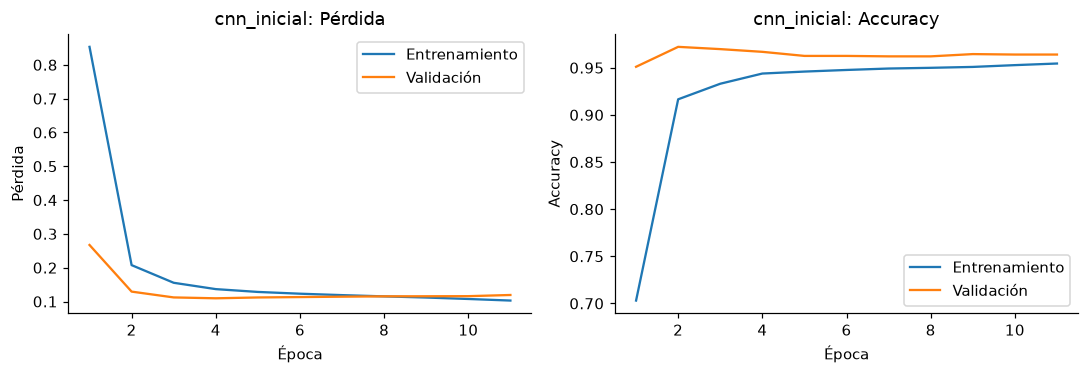

Brecha de accuracy en la época seleccionada: -0.0230
Una brecha aislada no demuestra sobreajuste; se interpreta junto con ambas curvas


In [9]:
def dibujar_historia(nombre):
    h = historiales[nombre]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metrica, titulo in zip(axes, ['loss', 'accuracy'], ['Pérdida', 'Accuracy']):
        ax.plot(np.arange(1, len(h[metrica]) + 1), h[metrica], label='Entrenamiento')
        ax.plot(np.arange(1, len(h[metrica]) + 1), h['val_' + metrica], label='Validación')
        ax.set(xlabel='Época', ylabel=titulo, title=f'{nombre}: {titulo}')
        ax.legend()
    fig.tight_layout()
    fig.savefig(ROOT / f'reports/figures/curvas_{nombre}.png')
    plt.show()

dibujar_historia('cnn_inicial')
h = historiales['cnn_inicial']
e = registros[0]['mejor_epoca'] - 1
print(f'Brecha de accuracy en la época seleccionada: {h["accuracy"][e] - h["val_accuracy"][e]:.4f}')
print('Una brecha aislada no demuestra sobreajuste; se interpreta junto con ambas curvas')

## 4. Ajuste del modelo
En la primera iteración se añade Dropout de 0.35 antes de la salida; con ello se busca reducir la dependencia de unas pocas activaciones y mejorar la generalización. En la segunda iteración se mantiene esa regularización y se reduce la tasa de aprendizaje de 0.001 a 0.0005; así se explora si actualizaciones más pequeñas mejoran el ajuste.

Los tres experimentos utilizan las mismas particiones, semilla, tamaño de lote, máximo de épocas y criterio de detención; por ello, las comparaciones permiten observar el efecto de los cambios bajo estas condiciones. Sin embargo, una sola semilla no demuestra que el efecto se repita siempre; si una variante empeora, se documenta y no se presenta como una mejora.

Se ejecuta la primera iteración con Dropout; después se revisan sus curvas para observar si cambia la relación entre entrenamiento y validación.

Epoch 1/35


83/83 - 5s - 56ms/step - accuracy: 0.6237 - loss: 0.9841 - val_accuracy: 0.9164 - val_loss: 0.3353


Epoch 2/35


83/83 - 2s - 27ms/step - accuracy: 0.8970 - loss: 0.2900 - val_accuracy: 0.9697 - val_loss: 0.1289


Epoch 3/35


83/83 - 2s - 23ms/step - accuracy: 0.9214 - loss: 0.2009 - val_accuracy: 0.9702 - val_loss: 0.1091


... (21 outputs left out)

83/83 - 1s - 17ms/step - accuracy: 0.9573 - loss: 0.1031 - val_accuracy: 0.9640 - val_loss: 0.1118


Epoch 15/35


83/83 - 2s - 25ms/step - accuracy: 0.9545 - loss: 0.1040 - val_accuracy: 0.9621 - val_loss: 0.1181


,modelo,dropout,tasa,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,cnn_dropout,0.35,0.001,15,8,0.098016,0.964457,0.965283,31.861915


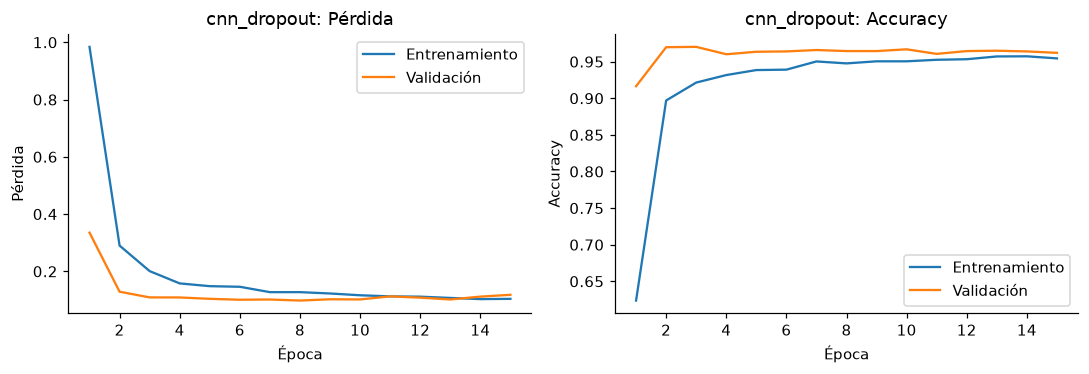

In [10]:
modelo_regularizado = entrenar('cnn_dropout', dropout=0.35, tasa=0.001)
dibujar_historia('cnn_dropout')

**Lectura de las curvas:** en esta ejecución, el accuracy de validación supera al de entrenamiento en varias épocas; esto no demuestra por sí solo una fuga de datos. Dropout está activo durante entrenamiento y desactivado durante evaluación; además, los participantes de ambas particiones son distintos y pueden presentar diferente dificultad. Por ello, se conservan las comprobaciones de separación por persona y se interpretan las curvas en conjunto.

Se ejecuta la segunda iteración con una tasa de aprendizaje menor; se conserva Dropout para comparar directamente el efecto de este ajuste adicional.

Epoch 1/35


83/83 - 4s - 54ms/step - accuracy: 0.5047 - loss: 1.2698 - val_accuracy: 0.8833 - val_loss: 0.7327


Epoch 2/35


83/83 - 2s - 18ms/step - accuracy: 0.8279 - loss: 0.5362 - val_accuracy: 0.9621 - val_loss: 0.2522


Epoch 3/35


83/83 - 1s - 16ms/step - accuracy: 0.8905 - loss: 0.3018 - val_accuracy: 0.9673 - val_loss: 0.1491


... (29 outputs left out)

83/83 - 2s - 26ms/step - accuracy: 0.9539 - loss: 0.1103 - val_accuracy: 0.9520 - val_loss: 0.1355


Epoch 19/35


83/83 - 2s - 24ms/step - accuracy: 0.9537 - loss: 0.1084 - val_accuracy: 0.9606 - val_loss: 0.1221


,modelo,dropout,tasa,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,cnn_dropout_lr,0.35,0.0005,19,12,0.100626,0.963016,0.963788,40.610436


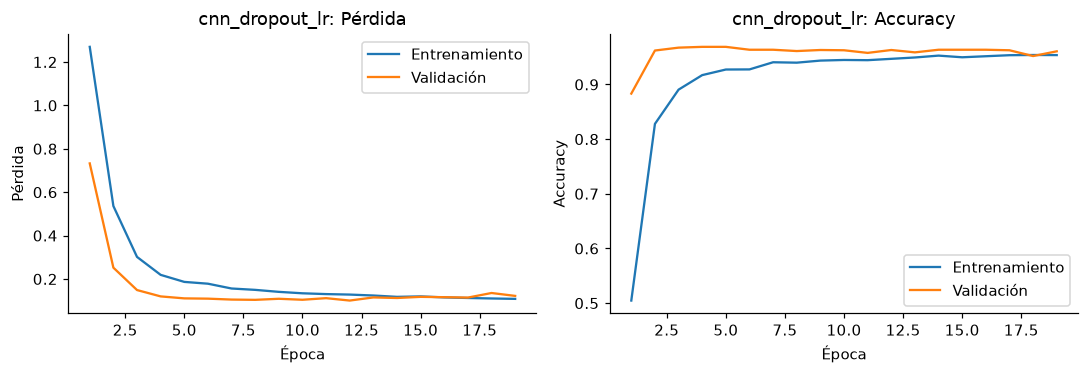

In [11]:
modelo_ajustado = entrenar('cnn_dropout_lr', dropout=0.35, tasa=0.0005)
dibujar_historia('cnn_dropout_lr')

Se comparan los resultados y se selecciona el modelo por F1 macro de validación; además, se explican los cambios observados sin atribuir una mejora a técnicas que no la consiguieron.

In [12]:
comparacion = pd.DataFrame(registros)
comparacion.to_csv(ROOT / 'reports/comparacion_validacion.csv', index=False)
display(comparacion.round(4))
orden = comparacion.sort_values(['val_f1_macro', 'val_loss'], ascending=[False, True], kind='stable')
ganador = orden.iloc[0]['modelo']
modelo_final = keras.models.load_model(ROOT / f'models/{ganador}.keras')
modelo_final.save(ROOT / 'models/modelo_final.keras')
base, regularizado, ajustado = registros
delta_dropout = regularizado['val_f1_macro'] - base['val_f1_macro']
delta_tasa = ajustado['val_f1_macro'] - regularizado['val_f1_macro']
texto_ajustes = f"""### Interpretación de los ajustes
Dropout cambió el F1 macro de validación en **{delta_dropout * 100:+.2f} puntos porcentuales** frente al modelo inicial; {'el resultado es compatible con una menor dependencia de activaciones particulares' if delta_dropout > 0 else 'en esta ejecución no produjo una mejora, por lo que la regularización pudo limitar información útil'}.

Reducir la tasa de aprendizaje cambió el F1 macro en **{delta_tasa * 100:+.2f} puntos porcentuales** frente a la variante con Dropout; {'las actualizaciones más pequeñas son una explicación plausible de la mejora observada' if delta_tasa > 0 else 'el paso menor no mejoró la métrica dentro del presupuesto de entrenamiento utilizado'}.

Se seleccionó **{ganador}**, con F1 macro de validación de **{orden.iloc[0]['val_f1_macro']:.4f}**; estas explicaciones son hipótesis compatibles con los resultados, y requerirían varias semillas y particiones para confirmarse.
"""
display(Markdown(texto_ajustes))
(ROOT / 'reports/analisis_ajustes.md').write_text(texto_ajustes, encoding='utf-8')

,modelo,dropout,tasa,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,cnn_inicial,0.00,0.0010,11,4,0.1095,0.9669,0.9672,22.9408
1,cnn_dropout,0.35,0.0010,15,8,0.0980,0.9645,0.9653,31.8619
2,cnn_dropout_lr,0.35,0.0005,19,12,0.1006,0.9630,0.9638,40.6104


### Interpretación de los ajustes
Dropout cambió el F1 macro de validación en **-0.19 puntos porcentuales** frente al modelo inicial; en esta ejecución no produjo una mejora, por lo que la regularización pudo limitar información útil.

Reducir la tasa de aprendizaje cambió el F1 macro en **-0.15 puntos porcentuales** frente a la variante con Dropout; el paso menor no mejoró la métrica dentro del presupuesto de entrenamiento utilizado.

Se seleccionó **cnn_inicial**, con F1 macro de validación de **0.9672**; estas explicaciones son hipótesis compatibles con los resultados, y requerirían varias semillas y particiones para confirmarse.


641

**Pérdida frente a F1:** en la ejecución incluida, Dropout sí redujo la pérdida de validación frente a la CNN inicial; sin embargo, su F1 macro fue ligeramente menor. La entropía cruzada considera las puntuaciones asignadas a las clases, mientras que F1 se calcula a partir de la clase elegida; por ello, ambas métricas pueden cambiar en direcciones diferentes. Se mantiene la regla de selección definida antes del entrenamiento; la mejor pérdida no reemplaza al F1 como criterio principal.

## 5. Resultados
Una vez seleccionado y guardado el modelo, se abre la evaluación de prueba; de esta forma, los resultados representan el desempeño con participantes que no intervinieron en el entrenamiento ni en la elección de hiperparámetros. Se reportan accuracy, F1 macro, métricas por actividad y una matriz de confusión; además, se revisa el desempeño por persona para detectar diferencias que un promedio puede ocultar.

No se reajusta el modelo después de observar estos resultados; por tanto, la prueba conserva su función de evaluación final. Las ventanas de una misma persona no son independientes, así que tampoco se interpreta su cantidad como si fueran miles de participantes distintos.

Se calculan las métricas finales con la partición de prueba reservada; posteriormente, se guardan el reporte por clase y las predicciones para que los resultados puedan revisarse.

In [13]:
prob_test = modelo_final.predict(X_test, verbose=0)
pred_test = prob_test.argmax(axis=1)
loss_test = float(modelo_final.evaluate(X_test, y_test, verbose=0)[0])
metricas = {'modelo_seleccionado': ganador, 'test_loss': loss_test,
            'test_accuracy': float(accuracy_score(y_test, pred_test)),
            'test_f1_macro': float(f1_score(y_test, pred_test, average='macro')),
            'ventanas_prueba': len(y_test), 'personas_prueba': len(set(personas_test))}
display(pd.DataFrame([metricas]))
reporte = pd.DataFrame(classification_report(y_test, pred_test, labels=np.arange(6),
                       target_names=CLASES, output_dict=True, zero_division=0)).T
display(reporte.round(4))
reporte.to_csv(ROOT / 'reports/reporte_clasificacion.csv')
(ROOT / 'reports/metricas_prueba.json').write_text(json.dumps(metricas, indent=2))
pd.DataFrame({'persona': personas_test, 'real': y_test, 'prediccion': pred_test,
              'puntuacion_softmax': prob_test.max(axis=1)}).to_csv(ROOT / 'reports/predicciones_prueba.csv', index=False)

,modelo_seleccionado,test_loss,test_accuracy,test_f1_macro,ventanas_prueba,personas_prueba
0,cnn_inicial,0.271694,0.895826,0.895632,2947,9


,precision,recall,f1-score,support
Caminar,0.9954,0.8710,0.9290,496.0000
Subir escaleras,0.9609,0.9384,0.9495,471.0000
Bajar escaleras,0.8194,0.9833,0.8939,420.0000
Sentarse,0.8178,0.7495,0.7821,491.0000
Estar de pie,0.7975,0.8440,0.8201,532.0000
Acostarse,1.0000,0.9981,0.9991,537.0000
accuracy,0.8958,0.8958,0.8958,0.8958
macro avg,0.8985,0.8974,0.8956,2947.0000
weighted avg,0.9003,0.8958,0.8959,2947.0000


Se representa la matriz de confusión y se revisa cada participante; así se identifican las actividades y personas en las que el modelo presenta más dificultades.

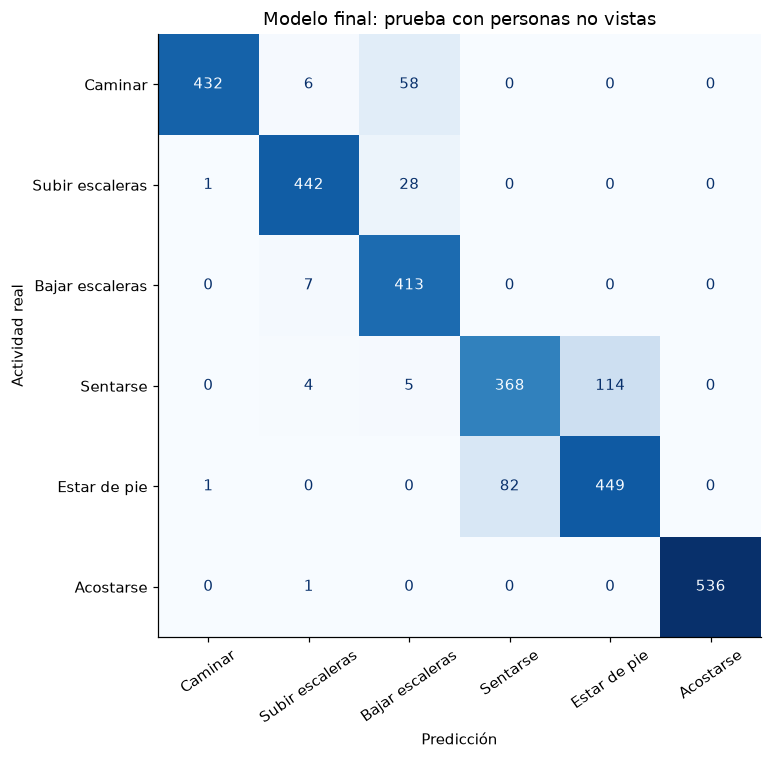

,persona,ventanas,accuracy,f1_macro
0,2,302,0.8974,0.8781
1,4,317,0.8991,0.8975
2,9,288,0.7882,0.7515
3,10,294,0.6395,0.6322
4,12,320,0.9344,0.9302
5,13,327,0.9694,0.9677
6,18,364,0.9670,0.9677
7,20,354,0.9040,0.8959
8,24,381,1.0000,1.0000


Confusión más frecuente: Sentarse → Estar de pie; 114 ventanas


In [14]:
matriz = confusion_matrix(y_test, pred_test, labels=np.arange(6))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=35)
ax.set(title='Modelo final: prueba con personas no vistas', xlabel='Predicción', ylabel='Actividad real')
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/matriz_confusion.png')
plt.show()
por_persona = pd.DataFrame([
    {'persona': int(p), 'ventanas': int(sum(personas_test == p)),
     'accuracy': accuracy_score(y_test[personas_test == p], pred_test[personas_test == p]),
     'f1_macro': f1_score(y_test[personas_test == p], pred_test[personas_test == p],
                          labels=np.arange(6), average='macro', zero_division=0)}
    for p in np.unique(personas_test)])
display(por_persona.round(4))
por_persona.to_csv(ROOT / 'reports/resultados_por_persona.csv', index=False)
sin_diagonal = matriz.copy()
np.fill_diagonal(sin_diagonal, 0)
real_error, pred_error = np.unravel_index(sin_diagonal.argmax(), sin_diagonal.shape)
if sin_diagonal.max() > 0:
    print(f'Confusión más frecuente: {CLASES[real_error]} → {CLASES[pred_error]}; {sin_diagonal.max()} ventanas')
else:
    print('No se registraron errores en esta partición')

**Interpretación de los errores:** en esta ejecución, la confusión principal aparece entre la postura sentada y la postura de pie; ambas implican poco movimiento, por lo que algunas ventanas pueden ser difíciles de distinguir. Esta explicación es plausible, pero la matriz por sí sola no demuestra la causa; también intervienen la posición del teléfono y las diferencias entre participantes. Asimismo, la diferencia entre validación y prueba muestra que un buen resultado con un grupo de personas no asegura el mismo rendimiento con otro; por eso se conserva la prueba sin utilizarla para nuevos ajustes.

## 6. Conclusiones
Las conclusiones siguientes se construyen con las métricas realmente obtenidas; de esta manera, se evita afirmar que una técnica funcionó antes de comprobarlo. El alcance se limita a las seis actividades, el protocolo y los participantes del conjunto utilizado; además, los resultados no garantizan el mismo desempeño si cambia la posición del teléfono, la población o el dispositivo.

Se redacta una conclusión basada en la comparación y la prueba final; asimismo, se señalan limitaciones y propuestas de mejora que podrían evaluarse en un trabajo posterior.

In [15]:
mejora = float(orden.iloc[0]['val_f1_macro'] - base['val_f1_macro'])
peor_clase = reporte.loc[CLASES, 'f1-score'].idxmin()
conclusion = f"""El modelo seleccionado fue **{ganador}**; obtuvo **{metricas['test_accuracy']:.2%} de accuracy** y **{metricas['test_f1_macro']:.4f} de F1 macro** en {len(y_test)} ventanas de prueba, correspondientes a {len(set(personas_test))} personas no vistas.

Frente a la CNN inicial, la mejor configuración cambió el F1 macro de validación en **{mejora * 100:+.2f} puntos porcentuales**; por tanto, {'los ajustes aportaron una mejora medible en esta partición' if mejora > 0 else 'los ajustes no superaron el punto de partida y se conservó el modelo inicial'}. El análisis anterior permite distinguir el efecto observado de Dropout y de la tasa de aprendizaje; sin embargo, no establece una causa definitiva a partir de una sola ejecución.

La actividad con menor F1 fue **{peor_clase}**, con **{reporte.loc[peor_clase, 'f1-score']:.4f}**; además, el accuracy por persona varió entre **{por_persona.accuracy.min():.2%}** y **{por_persona.accuracy.max():.2%}**, lo que muestra que el promedio no describe todos los casos de la misma forma.

Como siguiente paso, convendría repetir la comparación con varias semillas y validación por grupos; también se podría estudiar una LSTM o incorporar datos de otros dispositivos. Esas decisiones deberían tomarse sin reutilizar esta prueba para seleccionar nuevos modelos; si se ajusta a partir de sus errores, se necesitaría una nueva prueba independiente.

Finalmente, las puntuaciones softmax no son probabilidades calibradas de certeza; la aplicación clasifica señales que respetan el formato de UCI HAR y no transforma automáticamente registros arbitrarios de un teléfono.
"""
display(Markdown(conclusion))
(ROOT / 'reports/conclusiones.md').write_text(conclusion, encoding='utf-8')

El modelo seleccionado fue **cnn_inicial**; obtuvo **89.58% de accuracy** y **0.8956 de F1 macro** en 2947 ventanas de prueba, correspondientes a 9 personas no vistas.

Frente a la CNN inicial, la mejor configuración cambió el F1 macro de validación en **+0.00 puntos porcentuales**; por tanto, los ajustes no superaron el punto de partida y se conservó el modelo inicial. El análisis anterior permite distinguir el efecto observado de Dropout y de la tasa de aprendizaje; sin embargo, no establece una causa definitiva a partir de una sola ejecución.

La actividad con menor F1 fue **Sentarse**, con **0.7821**; además, el accuracy por persona varió entre **63.95%** y **100.00%**, lo que muestra que el promedio no describe todos los casos de la misma forma.

Como siguiente paso, convendría repetir la comparación con varias semillas y validación por grupos; también se podría estudiar una LSTM o incorporar datos de otros dispositivos. Esas decisiones deberían tomarse sin reutilizar esta prueba para seleccionar nuevos modelos; si se ajusta a partir de sus errores, se necesitaría una nueva prueba independiente.

Finalmente, las puntuaciones softmax no son probabilidades calibradas de certeza; la aplicación clasifica señales que respetan el formato de UCI HAR y no transforma automáticamente registros arbitrarios de un teléfono.


1338

## 7. Aplicación
Se implementa una función que recibe la ruta de un archivo `.npy` con una ventana de forma `(128, 9)`, o varias con forma `(n, 128, 9)`; la salida incluye la actividad y las puntuaciones de las seis clases. Los canales deben seguir el orden documentado y conservar el filtrado, la frecuencia y las unidades del conjunto original; la normalización ya está incorporada al modelo.

Los ejemplos que se generan y evalúan en este cuaderno provienen de personas de prueba y son nuevos respecto al entrenamiento; no se presentan como una recolección externa. Para una demostración con datos propios sería necesario reproducir el procesamiento de los sensores antes de llamar a la función.

Se carga el modelo guardado y se define la función de predicción; además, se comprueba que el archivo tenga las dimensiones correctas y no contenga valores inválidos.

In [16]:
modelo_cargado = keras.models.load_model(ROOT / 'models/modelo_final.keras')
def predecir_actividad(ruta_archivo, modelo=modelo_cargado):
    senales = np.load(ruta_archivo, allow_pickle=False)
    if senales.ndim == 2:
        senales = senales[np.newaxis, ...]
    if senales.ndim != 3 or senales.shape[1:] != (128, 9) or len(senales) == 0:
        raise ValueError('Se requiere una ventana (128, 9) o un lote (n, 128, 9)')
    senales = senales.astype(np.float32)
    if not np.isfinite(senales).all():
        raise ValueError('Las señales deben contener solo números finitos')
    prob = modelo.predict(senales, verbose=0)
    salida = pd.DataFrame(prob, columns=CLASES)
    salida.insert(0, 'actividad', np.array(CLASES)[prob.argmax(axis=1)])
    salida.insert(1, 'puntuacion_maxima', prob.max(axis=1))
    return salida

np.testing.assert_allclose(modelo_cargado.predict(X_test[:8], verbose=0), prob_test[:8], rtol=1e-5, atol=1e-6)
print('Modelo .keras recargado correctamente; sus predicciones coinciden con las originales')

Modelo .keras recargado correctamente; sus predicciones coinciden con las originales


Se guardan seis ventanas de prueba, una por actividad, y se pasan por la función; después se muestran las etiquetas reales junto con las predicciones para comprobar el funcionamiento de la aplicación.

In [17]:
ejemplos_idx = np.array([np.flatnonzero(y_test == c)[0] for c in range(6)])
np.save(ROOT / 'examples/actividades.npy', X_test[ejemplos_idx])
np.save(ROOT / 'examples/ventana.npy', X_test[ejemplos_idx[0]])
ejemplos = predecir_actividad(ROOT / 'examples/actividades.npy')
ejemplos.insert(0, 'real', np.array(CLASES)[y_test[ejemplos_idx]])
display(ejemplos.round(4))
ejemplos.to_csv(ROOT / 'reports/predicciones_ejemplo.csv', index=False)
(ROOT / 'examples/procedencia.json').write_text(json.dumps({
    'origen': 'Partición oficial de prueba UCI HAR; ejemplos no usados para entrenar',
    'indices_base_cero': ejemplos_idx.tolist(),
    'personas': personas_test[ejemplos_idx].tolist(), 'etiquetas': y_test[ejemplos_idx].tolist()
}, ensure_ascii=False, indent=2), encoding='utf-8')

,real,actividad,puntuacion_maxima,Caminar,Subir escaleras,Bajar escaleras,Sentarse,Estar de pie,Acostarse
0,Caminar,Caminar,0.9573,0.9573,0.0036,0.0004,0.0060,0.0327,0.0000
1,Subir escaleras,Subir escaleras,0.9989,0.0009,0.9989,0.0003,0.0000,0.0000,0.0000
2,Bajar escaleras,Bajar escaleras,0.9964,0.0013,0.0022,0.9964,0.0000,0.0000,0.0000
3,Sentarse,Estar de pie,0.8039,0.0022,0.0002,0.0001,0.1934,0.8039,0.0002
4,Estar de pie,Estar de pie,0.9851,0.0023,0.0007,0.0001,0.0117,0.9851,0.0000
5,Acostarse,Acostarse,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


290

**Lectura de la demostración:** los seis ejemplos se eligieron mediante una regla fija, tomando la primera ventana de cada clase; no se seleccionaron únicamente aciertos. En la ejecución incluida, la ventana de la postura sentada se clasificó como estar de pie; este error coincide con una dificultad observada en la evaluación general y muestra que una puntuación alta no garantiza una predicción correcta.

### Referencias y correspondencia con la actividad
- **Datos reales y fuente:** sección 2; descarga original de [UCI HAR](https://doi.org/10.24432/C54S4K).
- **TensorFlow + Keras y capas especializadas:** sección 3; [documentación de Conv1D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv1D).
- **Evaluación inicial y ajustes:** secciones 3 y 4; comparación de tres configuraciones con validación por personas.
- **Evaluación final y conclusiones:** secciones 5 y 6; prueba reservada, métricas, errores y limitaciones.
- **Predicciones y modelo entrenado:** sección 7 y `models/modelo_final.keras`; [formato de guardado Keras](https://keras.io/api/models/model_saving_apis/model_saving_and_loading/).